In [1]:
from pathlib import Path
import pandas as pd
import xml.etree.ElementTree as ET
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

DATASET_ROOT = Path("dataset")

MAIN_DIR = DATASET_ROOT / "main"
BOVINE_DIR = MAIN_DIR / "Indian_bovine_breeds"
CSV_PATH = MAIN_DIR / "bovine_breeds_metadata.csv"

OTHER_DIR = DATASET_ROOT / "other" / "Popular Animals Dataset"
OTHER_IMAGES_DIR = OTHER_DIR / "images"
OTHER_ANNOTATIONS_DIR = OTHER_DIR / "annotations"
OTHER_SPLIT_DIR = OTHER_DIR / "datasplit"

print("Dataset root:", DATASET_ROOT)
print("Bovine directory:", BOVINE_DIR)
print("Bovine CSV:", CSV_PATH)
print("Other dataset:", OTHER_DIR)

Dataset root: dataset
Bovine directory: dataset/main/Indian_bovine_breeds
Bovine CSV: dataset/main/bovine_breeds_metadata.csv
Other dataset: dataset/other/Popular Animals Dataset


In [2]:
paths_to_check = {
    "Dataset root": DATASET_ROOT,
    "Main directory": MAIN_DIR,
    "Indian bovine breeds": BOVINE_DIR,
    "Bovine metadata CSV": CSV_PATH,
    "Other dataset": OTHER_DIR,
    "Other images": OTHER_IMAGES_DIR,
    "Other annotations": OTHER_ANNOTATIONS_DIR,
    "Other datasplit": OTHER_SPLIT_DIR,
}

for name, path in paths_to_check.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"{status:8} | {name:25} | {path}")

OK       | Dataset root              | dataset
OK       | Main directory            | dataset/main
OK       | Indian bovine breeds      | dataset/main/Indian_bovine_breeds
OK       | Bovine metadata CSV       | dataset/main/bovine_breeds_metadata.csv
OK       | Other dataset             | dataset/other/Popular Animals Dataset
OK       | Other images              | dataset/other/Popular Animals Dataset/images
OK       | Other annotations         | dataset/other/Popular Animals Dataset/annotations
OK       | Other datasplit           | dataset/other/Popular Animals Dataset/datasplit


In [3]:
bovine_df = pd.read_csv(CSV_PATH)

print("Number of rows:", len(bovine_df))
print("Number of columns:", len(bovine_df.columns))

print("\nColumns:")
print(bovine_df.columns.tolist())

print("\nFirst 5 rows:")
display(bovine_df.head())

Number of rows: 5948
Number of columns: 4

Columns:
['image_id', 'breed', 'path', 'file extension']

First 5 rows:


,image_id,breed,path,file extension
0,Alambadi_1.png,Alambadi,Alambadi\Alambadi_1.png,png
1,Alambadi_10.png,Alambadi,Alambadi\Alambadi_10.png,png
2,Alambadi_100.jpg,Alambadi,Alambadi\Alambadi_100.jpg,jpg
3,Alambadi_101.png,Alambadi,Alambadi\Alambadi_101.png,png
4,Alambadi_11.png,Alambadi,Alambadi\Alambadi_11.png,png


In [4]:
with open(CSV_PATH, "r", encoding="utf-8-sig") as f:
    for i in range(6):
        print(repr(f.readline().rstrip("\n")))

print("\nPandas index information:")
print("Index name:", bovine_df.index.name)
print("Index type:", type(bovine_df.index).__name__)
print("Index values:", bovine_df.index[:5].tolist())

'image_id,breed,path,file extension'
'Alambadi_1.png,Alambadi,Alambadi\\Alambadi_1.png,png'
'Alambadi_10.png,Alambadi,Alambadi\\Alambadi_10.png,png'
'Alambadi_100.jpg,Alambadi,Alambadi\\Alambadi_100.jpg,jpg'
'Alambadi_101.png,Alambadi,Alambadi\\Alambadi_101.png,png'
'Alambadi_11.png,Alambadi,Alambadi\\Alambadi_11.png,png'

Pandas index information:
Index name: None
Index type: RangeIndex
Index values: [0, 1, 2, 3, 4]


In [5]:
breed_counts = bovine_df["breed"].value_counts().sort_index()

print("Number of unique breeds:", bovine_df["breed"].nunique())

print("\nBreed names and image counts:")
display(breed_counts.to_frame("image_count"))

Number of unique breeds: 41

Breed names and image counts:


,image_count
breed,
Alambadi,99
Amritmahal,94
Ayrshire,234
Banni,109
Bargur,94
Bhadawari,86
Brown_Swiss,225
Dangi,82
Deoni,99


In [6]:
BUFFALO_BREEDS = {
    "Banni",
    "Bhadawari",
    "Jaffrabadi",
    "Mehsana",
    "Murrah",
    "Nagpuri",
    "Nili_Ravi",
    "Surti",
    "Toda"
}

# Map each breed to a species
bovine_df["species"] = bovine_df["breed"].apply(
    lambda breed: "Buffalo" if breed in BUFFALO_BREEDS else "Cattle"
)

# Show species counts
print("Species counts:")
display(bovine_df["species"].value_counts())

print("\nBreeds mapped as Buffalo:")
print(sorted(bovine_df.loc[
    bovine_df["species"] == "Buffalo", "breed"
].unique()))

print("\nBreeds mapped as Cattle:")
print(sorted(bovine_df.loc[
    bovine_df["species"] == "Cattle", "breed"
].unique()))

Species counts:


species
Cattle     4919
Buffalo    1029
Name: count, dtype: int64


Breeds mapped as Buffalo:
['Banni', 'Bhadawari', 'Jaffrabadi', 'Mehsana', 'Murrah', 'Nagpuri', 'Nili_Ravi', 'Surti', 'Toda']

Breeds mapped as Cattle:
['Alambadi', 'Amritmahal', 'Ayrshire', 'Bargur', 'Brown_Swiss', 'Dangi', 'Deoni', 'Gir', 'Guernsey', 'Hallikar', 'Hariana', 'Holstein_Friesian', 'Jersey', 'Kangayam', 'Kankrej', 'Kasargod', 'Kenkatha', 'Kherigarh', 'Khillari', 'Krishna_Valley', 'Malnad_gidda', 'Nagori', 'Nimari', 'Ongole', 'Pulikulam', 'Rathi', 'Red_Dane', 'Red_Sindhi', 'Sahiwal', 'Tharparkar', 'Umblachery', 'Vechur']


In [7]:
def get_image_path(row):

    relative_path = str(row["path"]).replace("\\", "/")
    return BOVINE_DIR / relative_path


# Create full paths in memory
bovine_df["full_path"] = bovine_df.apply(get_image_path, axis=1)

# Check whether each image actually exists
bovine_df["exists"] = bovine_df["full_path"].apply(lambda x: x.exists())

print("Total CSV records :", len(bovine_df))
print("Images found      :", bovine_df["exists"].sum())
print("Images missing    :", (~bovine_df["exists"]).sum())

# Show a few example paths
print("\nExample paths:")
display(
    bovine_df[["image_id", "breed", "full_path", "exists"]].head(10)
)

Total CSV records : 5948
Images found      : 5948
Images missing    : 0

Example paths:


,image_id,breed,full_path,exists
0,Alambadi_1.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
1,Alambadi_10.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
2,Alambadi_100.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
3,Alambadi_101.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
4,Alambadi_11.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
5,Alambadi_12.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
6,Alambadi_13.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
7,Alambadi_14.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
8,Alambadi_15.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True
9,Alambadi_16.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,True


In [8]:
annotation_files = sorted(OTHER_ANNOTATIONS_DIR.glob("*.xml"))

print("Number of annotation files:", len(annotation_files))

# Read all XML annotations
annotation_data = []

for xml_file in annotation_files:
    try:
        tree = ET.parse(xml_file)
        root = tree.getroot()

        # Get image filename
        filename_node = root.find("filename")
        filename = (
            filename_node.text.strip()
            if filename_node is not None and filename_node.text
            else None
        )

        # Get object labels
        labels = []

        for obj in root.findall("object"):
            name_node = obj.find("name")

            if name_node is not None and name_node.text:
                labels.append(name_node.text.strip())

        annotation_data.append({
            "annotation_file": xml_file.name,
            "filename": filename,
            "labels": labels
        })

    except Exception as e:
        print(f"Error reading {xml_file.name}: {e}")

other_annotations_df = pd.DataFrame(annotation_data)

print("\nFirst 10 annotation records:")
display(other_annotations_df.head(10))

Number of annotation files: 600

First 10 annotation records:


,annotation_file,filename,labels
0,002905f3-006679.xml,002905f3-006679.jpg,[Owca]
1,00d6601f-000122.xml,00d6601f-000122.jpg,[Kot]
2,012dd761-000523.xml,012dd761-000523.jpg,"[Koń, Człowiek]"
3,0243b9c8-001833.xml,0243b9c8-001833.jpg,[Człowiek]
4,02df1202-002176.xml,02df1202-002176.jpg,[Człowiek]
5,032376aa-007089.xml,032376aa-007089.jpg,[Pies]
6,041105ba-004212.xml,041105ba-004212.jpg,[Kot]
7,050d43f2-009748.xml,050d43f2-009748.jpg,[Pies]
8,053f9dc0-6f071bcc-00011.xml,053f9dc0-6f071bcc-00011.jpg,[Owca]
9,054c4710-005169.xml,054c4710-005169.jpg,[Kot]


In [9]:
label_counts = Counter()

for labels in other_annotations_df["labels"]:
    for label in labels:
        label_counts[label] += 1

print("Number of unique labels:", len(label_counts))
print("\nLabels found:")

for label, count in label_counts.most_common():
    print(f"{label:20} -> {count}")

Number of unique labels: 6

Labels found:
Człowiek             -> 307
Krowa                -> 196
Owca                 -> 166
Pies                 -> 141
Koń                  -> 134
Kot                  -> 111


In [10]:
# Translate
POLISH_TO_ENGLISH = {
    "Człowiek": "Person",
    "Krowa": "Cow",
    "Owca": "Sheep",
    "Pies": "Dog",
    "Koń": "Horse",
    "Kot": "Cat"
}

# Convert the list of labels in each annotation
other_annotations_df["english_labels"] = other_annotations_df["labels"].apply(
    lambda labels: [POLISH_TO_ENGLISH[label] for label in labels]
)

print("First 10 translated annotations:")
display(
    other_annotations_df[
        ["filename", "labels", "english_labels"]
    ].head(10)
)

First 10 translated annotations:


,filename,labels,english_labels
0,002905f3-006679.jpg,[Owca],[Sheep]
1,00d6601f-000122.jpg,[Kot],[Cat]
2,012dd761-000523.jpg,"[Koń, Człowiek]","[Horse, Person]"
3,0243b9c8-001833.jpg,[Człowiek],[Person]
4,02df1202-002176.jpg,[Człowiek],[Person]
5,032376aa-007089.jpg,[Pies],[Dog]
6,041105ba-004212.jpg,[Kot],[Cat]
7,050d43f2-009748.jpg,[Pies],[Dog]
8,053f9dc0-6f071bcc-00011.jpg,[Owca],[Sheep]
9,054c4710-005169.jpg,[Kot],[Cat]


In [11]:
# Identify Other Images

# "Cow" is a target animal, so it must NOT be used as Other.
TARGET_LABELS = {"Cow"}

def classify_other_image(labels):
    if "Cow" in labels:
        return "Contains Cow"
    return "Other"


other_annotations_df["image_category"] = (
    other_annotations_df["english_labels"]
    .apply(classify_other_image)
)

print("Image-level category counts:")
display(
    other_annotations_df["image_category"].value_counts()
)

print("\nExamples containing Cow:")
display(
    other_annotations_df[
        other_annotations_df["image_category"] == "Contains Cow"
    ][
        ["filename", "english_labels"]
    ].head(10)
)

print("\nExamples suitable for Other:")
display(
    other_annotations_df[
        other_annotations_df["image_category"] == "Other"
    ][
        ["filename", "english_labels"]
    ].head(10)
)

Image-level category counts:


image_category
Other           499
Contains Cow    101
Name: count, dtype: int64


Examples containing Cow:


,filename,english_labels
24,0cb02245-006935.jpg,[Cow]
33,106fb509-004585.jpg,"[Cow, Cow, Cow, Cow, Cow, Cow, Cow, Cow, Cow, ..."
35,119c13e3-007075.jpg,"[Cow, Cow]"
43,14b605c7-002695.jpg,"[Cow, Cow, Cow]"
47,15b0590c-002634.jpg,"[Cow, Cow]"
49,16f0d9f1-000827.jpg,"[Cow, Cow]"
52,18174be4-000770.jpg,"[Cow, Person]"
55,19082c35-009245.jpg,"[Cow, Cow]"
63,1d28cb7c-007939.jpg,[Cow]
69,1f4063da-000491.jpg,[Cow]



Examples suitable for Other:


,filename,english_labels
0,002905f3-006679.jpg,[Sheep]
1,00d6601f-000122.jpg,[Cat]
2,012dd761-000523.jpg,"[Horse, Person]"
3,0243b9c8-001833.jpg,[Person]
4,02df1202-002176.jpg,[Person]
5,032376aa-007089.jpg,[Dog]
6,041105ba-004212.jpg,[Cat]
7,050d43f2-009748.jpg,[Dog]
8,053f9dc0-6f071bcc-00011.jpg,[Sheep]
9,054c4710-005169.jpg,[Cat]


In [12]:
# Keep only images that do NOT contain Cow
other_candidate_df = other_annotations_df[
    other_annotations_df["image_category"] == "Other"
].copy()

# Build the actual image path
other_candidate_df["full_path"] = other_candidate_df["filename"].apply(
    lambda filename: OTHER_IMAGES_DIR / filename
)

# Check whether each image exists
other_candidate_df["exists"] = other_candidate_df["full_path"].apply(
    lambda path: path.exists()
)

print("Other candidate images :", len(other_candidate_df))
print("Images found            :", other_candidate_df["exists"].sum())
print("Images missing          :", (~other_candidate_df["exists"]).sum())

print("\nExample paths:")
display(
    other_candidate_df[
        ["filename", "english_labels", "full_path", "exists"]
    ].head(10)
)

Other candidate images : 499
Images found            : 499
Images missing          : 0

Example paths:


,filename,english_labels,full_path,exists
0,002905f3-006679.jpg,[Sheep],dataset/other/Popular Animals Dataset/images/0...,True
1,00d6601f-000122.jpg,[Cat],dataset/other/Popular Animals Dataset/images/0...,True
2,012dd761-000523.jpg,"[Horse, Person]",dataset/other/Popular Animals Dataset/images/0...,True
3,0243b9c8-001833.jpg,[Person],dataset/other/Popular Animals Dataset/images/0...,True
4,02df1202-002176.jpg,[Person],dataset/other/Popular Animals Dataset/images/0...,True
5,032376aa-007089.jpg,[Dog],dataset/other/Popular Animals Dataset/images/0...,True
6,041105ba-004212.jpg,[Cat],dataset/other/Popular Animals Dataset/images/0...,True
7,050d43f2-009748.jpg,[Dog],dataset/other/Popular Animals Dataset/images/0...,True
8,053f9dc0-6f071bcc-00011.jpg,[Sheep],dataset/other/Popular Animals Dataset/images/0...,True
9,054c4710-005169.jpg,[Cat],dataset/other/Popular Animals Dataset/images/0...,True


In [13]:
train_split_file = OTHER_SPLIT_DIR / "train.txt"
test_split_file = OTHER_SPLIT_DIR / "test.txt"


def read_split_file(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        return [
            line.strip()
            for line in f
            if line.strip()
        ]


other_train_ids = read_split_file(train_split_file)
other_test_ids = read_split_file(test_split_file)

print("Number of train IDs:", len(other_train_ids))
print("Number of test IDs :", len(other_test_ids))

print("\nFirst 10 train IDs:")
print(other_train_ids[:10])

print("\nFirst 10 test IDs:")
print(other_test_ids[:10])

Number of train IDs: 450
Number of test IDs : 150

First 10 train IDs:
['00d6601f-000122', '041105ba-004212', '07b95f6d-005078', '09c904a7-004016', '0a9cfa29-004708', '10bfc4c7-003937', '1537c716-000019', '17611918-006595', '196838df-004076', '19740b63-004955']

First 10 test IDs:
['054c4710-005169', '0effa01b-005445', '20cf5f25-002677', '2a35856a-004654', '3d44cfe9-004185', '5ee3d44a-000044', '71939ab1-005715', '7d319282-008521', '829acca0-006105', '95d72c23-004345']


In [14]:
# Convert split IDs to sets for fast lookup
train_id_set = set(other_train_ids)
test_id_set = set(other_test_ids)

# Get the image ID without the .jpg extension
other_candidate_df["image_id"] = (
    other_candidate_df["filename"]
    .str.rsplit(".", n=1)
    .str[0]
)

# Assign the original dataset split
def get_split(image_id):
    if image_id in train_id_set:
        return "train"
    elif image_id in test_id_set:
        return "test"
    else:
        return "unknown"

other_candidate_df["split"] = (
    other_candidate_df["image_id"].apply(get_split)
)

print("Other images by split:")
display(
    other_candidate_df["split"].value_counts()
)

print("\nUnknown split images:")
display(
    other_candidate_df[
        other_candidate_df["split"] == "unknown"
    ][["filename", "english_labels"]].head(20)
)

Other images by split:


split
train    374
test     125
Name: count, dtype: int64


Unknown split images:


,filename,english_labels


In [15]:
# Count each English label within train/test
other_label_split_counts = (
    other_candidate_df
    .explode("english_labels")
    .groupby(["split", "english_labels"])
    .size()
    .unstack(fill_value=0)
)

print("Other dataset label distribution:")
display(other_label_split_counts)

print("\nTotal usable Other images:")
print("Train:", len(other_candidate_df[other_candidate_df["split"] == "train"]))
print("Test :", len(other_candidate_df[other_candidate_df["split"] == "test"]))
print("Total:", len(other_candidate_df))

Other dataset label distribution:


english_labels,Cat,Dog,Horse,Person,Sheep
split,,,,,
test,28,30,35,65,50
train,83,110,96,213,113



Total usable Other images:
Train: 374
Test : 125
Total: 499


In [16]:
# Make a copy so the original annotation dataframe stays unchanged
other_model_df = other_candidate_df.copy()

# All selected images belong to the generic "Other" class
other_model_df["label"] = "Other"

# Keep only the columns we need
other_model_df = other_model_df[
    [
        "image_id",
        "filename",
        "english_labels",
        "full_path",
        "split",
        "label"
    ]
].copy()

print("Other dataset metadata:")
display(other_model_df.head(10))

print("\nClass count:")
print(other_model_df["label"].value_counts())

print("\nSplit count:")
display(
    other_model_df["split"].value_counts().to_frame("image_count")
)

Other dataset metadata:


,image_id,filename,english_labels,full_path,split,label
0,002905f3-006679,002905f3-006679.jpg,[Sheep],dataset/other/Popular Animals Dataset/images/0...,train,Other
1,00d6601f-000122,00d6601f-000122.jpg,[Cat],dataset/other/Popular Animals Dataset/images/0...,train,Other
2,012dd761-000523,012dd761-000523.jpg,"[Horse, Person]",dataset/other/Popular Animals Dataset/images/0...,test,Other
3,0243b9c8-001833,0243b9c8-001833.jpg,[Person],dataset/other/Popular Animals Dataset/images/0...,train,Other
4,02df1202-002176,02df1202-002176.jpg,[Person],dataset/other/Popular Animals Dataset/images/0...,test,Other
5,032376aa-007089,032376aa-007089.jpg,[Dog],dataset/other/Popular Animals Dataset/images/0...,train,Other
6,041105ba-004212,041105ba-004212.jpg,[Cat],dataset/other/Popular Animals Dataset/images/0...,train,Other
7,050d43f2-009748,050d43f2-009748.jpg,[Dog],dataset/other/Popular Animals Dataset/images/0...,test,Other
8,053f9dc0-6f071bcc-00011,053f9dc0-6f071bcc-00011.jpg,[Sheep],dataset/other/Popular Animals Dataset/images/0...,train,Other
9,054c4710-005169,054c4710-005169.jpg,[Cat],dataset/other/Popular Animals Dataset/images/0...,test,Other



Class count:
label
Other    499
Name: count, dtype: int64

Split count:


,image_count
split,
train,374
test,125


In [17]:
# Creating Bovine Metadata

# Use only valid image files
bovine_model_df = bovine_df[
    bovine_df["exists"] == True
].copy()

# Final classification label
bovine_model_df["label"] = bovine_model_df["species"]

bovine_model_df["split"] = "unassigned"

# Keep the useful columns
bovine_model_df = bovine_model_df[
    [
        "image_id",
        "breed",
        "full_path",
        "species",
        "split",
        "label"
    ]
].copy()

print("Bovine metadata:")
display(bovine_model_df.head(10))

print("\nClass distribution:")
display(
    bovine_model_df["label"].value_counts().to_frame("image_count")
)

print("\nTotal bovine images:", len(bovine_model_df))

Bovine metadata:


,image_id,breed,full_path,species,split,label
0,Alambadi_1.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
1,Alambadi_10.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
2,Alambadi_100.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
3,Alambadi_101.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
4,Alambadi_11.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
5,Alambadi_12.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
6,Alambadi_13.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
7,Alambadi_14.png,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
8,Alambadi_15.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle
9,Alambadi_16.jpg,Alambadi,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Cattle,unassigned,Cattle



Class distribution:


,image_count
label,
Cattle,4919
Buffalo,1029



Total bovine images: 5948


In [18]:
# Combine Both Datasets

# Prepare bovine dataframe
bovine_combined = bovine_model_df[
    ["image_id", "full_path", "breed", "label", "split"]
].copy()

# Prepare Other dataframe
other_combined = other_model_df[
    ["image_id", "full_path", "english_labels", "label", "split"]
].copy()

# Add missing column so both dataframes have the same structure
bovine_combined["english_labels"] = None

# Arrange columns in the same order
bovine_combined = bovine_combined[
    ["image_id", "full_path", "breed", "english_labels", "label", "split"]
]

other_combined["breed"] = None

other_combined = other_combined[
    ["image_id", "full_path", "breed", "english_labels", "label", "split"]
]

# Combine
combined_df = pd.concat(
    [bovine_combined, other_combined],
    ignore_index=True
)

print("Total images:", len(combined_df))

print("\nClass distribution:")
display(
    combined_df["label"].value_counts().to_frame("image_count")
)

print("\nCurrent split distribution:")
display(
    combined_df.groupby(["split", "label"]).size().unstack(fill_value=0)
)

print("\nFirst 10 rows:")
display(combined_df.head(10))

Total images: 6447

Class distribution:


,image_count
label,
Cattle,4919
Buffalo,1029
Other,499



Current split distribution:


label,Buffalo,Cattle,Other
split,,,
test,0,0,125
train,0,0,374
unassigned,1029,4919,0



First 10 rows:


,image_id,full_path,breed,english_labels,label,split
0,Alambadi_1.png,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
1,Alambadi_10.png,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
2,Alambadi_100.jpg,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
3,Alambadi_101.png,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
4,Alambadi_11.png,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
5,Alambadi_12.jpg,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
6,Alambadi_13.png,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
7,Alambadi_14.png,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
8,Alambadi_15.jpg,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned
9,Alambadi_16.jpg,dataset/main/Indian_bovine_breeds/Alambadi/Ala...,Alambadi,None,Cattle,unassigned


In [19]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Split BOVINE data: 70% train, 15% validation, 15% test

bovine_data = combined_df[
    combined_df["label"].isin(["Cattle", "Buffalo"])
].copy()

bovine_train, bovine_temp = train_test_split(
    bovine_data,
    test_size=0.30,
    stratify=bovine_data["label"],
    random_state=RANDOM_STATE
)

bovine_val, bovine_test = train_test_split(
    bovine_temp,
    test_size=0.50,
    stratify=bovine_temp["label"],
    random_state=RANDOM_STATE
)

bovine_train["split"] = "train"
bovine_val["split"] = "validation"
bovine_test["split"] = "test"


# Split OTHER data
# Existing test set stays untouched.
# Existing train set → 80% train + 20% validation

other_data = combined_df[
    combined_df["label"] == "Other"
].copy()

other_train_original = other_data[
    other_data["split"] == "train"
].copy()

other_test = other_data[
    other_data["split"] == "test"
].copy()

other_train, other_val = train_test_split(
    other_train_original,
    test_size=0.20,
    stratify=other_train_original["english_labels"].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unknown"
    ),
    random_state=RANDOM_STATE
)

other_train["split"] = "train"
other_val["split"] = "validation"
other_test["split"] = "test"


# Combine final splits

final_df = pd.concat(
    [
        bovine_train,
        bovine_val,
        bovine_test,
        other_train,
        other_val,
        other_test
    ],
    ignore_index=True
)

# Shuffle the final dataframe
final_df = final_df.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)


# Display results

print("Final dataset size:", len(final_df))

print("\nClass distribution:")
display(
    final_df["label"]
    .value_counts()
    .to_frame("image_count")
)

print("\nSplit distribution:")
display(
    final_df["split"]
    .value_counts()
    .to_frame("image_count")
)

print("\nClass distribution by split:")
display(
    final_df
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

Final dataset size: 6447

Class distribution:


,image_count
label,
Cattle,4919
Buffalo,1029
Other,499



Split distribution:


,image_count
split,
train,4462
test,1018
validation,967



Class distribution by split:


label,Buffalo,Cattle,Other
split,,,
test,155,738,125
train,720,3443,299
validation,154,738,75


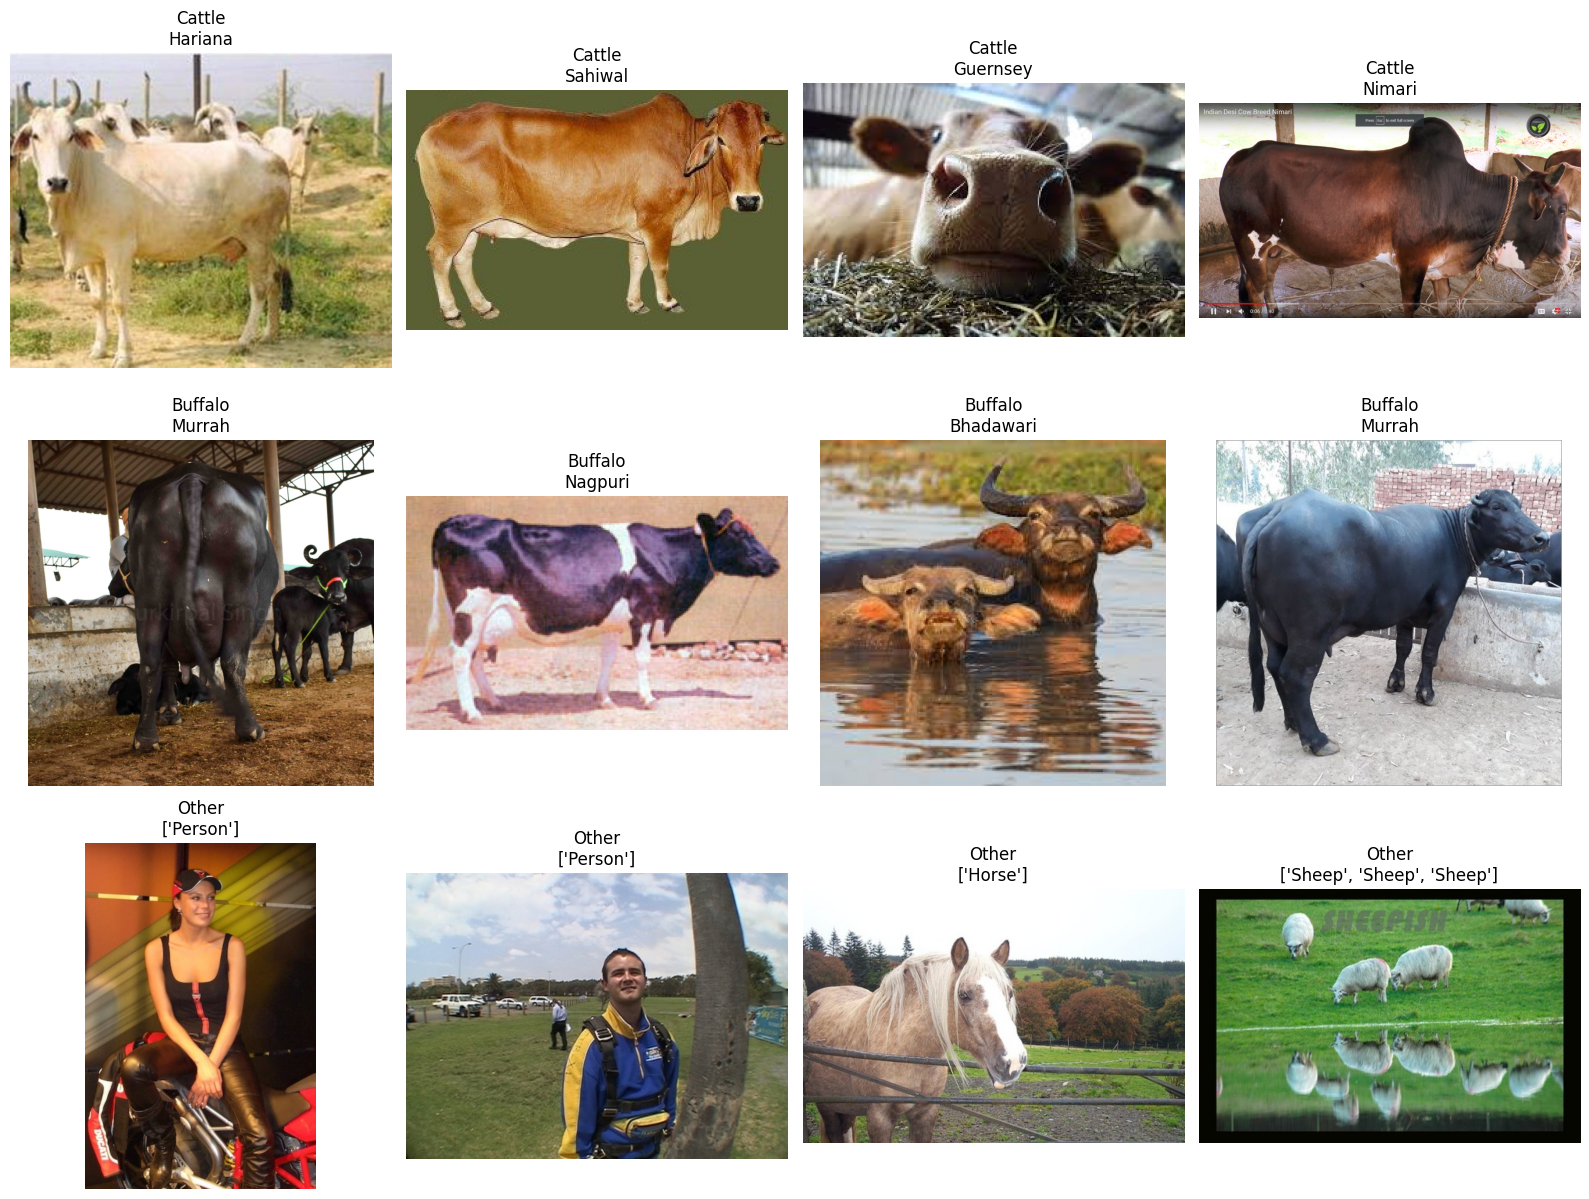

In [20]:
import random

# Number of images to display per class
SAMPLES_PER_CLASS = 4

classes = ["Cattle", "Buffalo", "Other"]

fig, axes = plt.subplots(
    len(classes),
    SAMPLES_PER_CLASS,
    figsize=(16, 12)
)

for row, class_name in enumerate(classes):

    class_data = final_df[
        (final_df["label"] == class_name) &
        (final_df["split"] == "train")
    ]

    samples = class_data.sample(
        min(SAMPLES_PER_CLASS, len(class_data)),
        random_state=42
    )

    for col, (_, record) in enumerate(samples.iterrows()):

        ax = axes[row, col]

        try:
            image = Image.open(record["full_path"]).convert("RGB")

            ax.imshow(image)
            ax.set_title(
                f"{class_name}\n{record['breed'] if pd.notna(record.get('breed')) else record['english_labels']}"
            )
            ax.axis("off")

        except Exception as e:
            ax.set_title(f"Error\n{record['image_id']}")
            ax.axis("off")
            print("Error loading:", record["full_path"])
            print(e)

plt.tight_layout()
plt.show()

In [21]:
# CHECK IMAGE VALIDITY AND DIMENSIONS

from collections import Counter

valid_count = 0
invalid_count = 0
size_counter = Counter()
invalid_files = []

for _, row in final_df.iterrows():
    image_path = row["full_path"]

    try:
        with Image.open(image_path) as img:
            # Force reading the image data
            img.verify()

        # Re-open after verify() to get dimensions
        with Image.open(image_path) as img:
            width, height = img.size
            size_counter[(width, height)] += 1

        valid_count += 1

    except Exception as e:
        invalid_count += 1
        invalid_files.append({
            "path": str(image_path),
            "error": str(e)
        })

print("Total images :", len(final_df))
print("Valid images  :", valid_count)
print("Invalid images:", invalid_count)

print("\nMost common image sizes:")
for size, count in size_counter.most_common(10):
    print(f"{size}: {count}")

if invalid_files:
    print("\nFirst invalid files:")
    display(pd.DataFrame(invalid_files).head(10))

Total images : 6447
Valid images  : 6447
Invalid images: 0

Most common image sizes:
(1920, 1080): 933
(1280, 720): 285
(275, 183): 214
(259, 194): 212
(800, 600): 195
(480, 360): 129
(225, 225): 115
(300, 168): 98
(320, 180): 90
(200, 200): 80


In [22]:
import torch
import torchvision

print("PyTorch version    :", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("\nCUDA available     :", torch.cuda.is_available())
print("CUDA version       :", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU name           :", torch.cuda.get_device_name(0))
    print("GPU count          :", torch.cuda.device_count())
else:
    print("GPU is NOT available to PyTorch")

PyTorch version    : 2.11.0+cu128
Torchvision version: 0.26.0+cu128

CUDA available     : True
CUDA version       : 12.8
GPU name           : NVIDIA GeForce RTX 4050 Laptop GPU
GPU count          : 1


In [23]:
# 24. DEVICE AND IMAGE TRANSFORMS

import torch
from torchvision import transforms

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# Image settings
IMAGE_SIZE = 224


# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation / test transformations
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


print("\nImage size:", IMAGE_SIZE)
print("Training transforms ready.")
print("Evaluation transforms ready.")

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

Image size: 224
Training transforms ready.
Evaluation transforms ready.


In [24]:
# 25. CREATE PYTORCH DATASETS AND DATALOADERS

from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Keep this class order fixed for training and prediction
CLASS_NAMES = ["Cattle", "Buffalo", "Other"]

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

print("Class mapping:", class_to_idx)


class AnimalDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True).copy()
        self.transform = transform

        # Ensure every label is supported
        unknown_labels = set(self.data["label"]) - set(CLASS_NAMES)
        if unknown_labels:
            raise ValueError(f"Unknown labels found: {unknown_labels}")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image_path = str(row["full_path"])
        label = class_to_idx[row["label"]]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Separate the metadata by split
train_df = final_df[final_df["split"] == "train"].copy()
val_df = final_df[final_df["split"] == "validation"].copy()
test_df = final_df[final_df["split"] == "test"].copy()


# Create datasets
train_dataset = AnimalDataset(
    train_df,
    transform=train_transform
)

val_dataset = AnimalDataset(
    val_df,
    transform=eval_transform
)

test_dataset = AnimalDataset(
    test_df,
    transform=eval_transform
)


# Create DataLoaders
BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)


# Verify the datasets and one training batch
print("\nDataset sizes:")
print("Train      :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test       :", len(test_dataset))
print("Total      :", len(train_dataset) + len(val_dataset) + len(test_dataset))

images, labels = next(iter(train_loader))

print("\nTraining batch:")
print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("Image dtype        :", images.dtype)
print("Label dtype        :", labels.dtype)
print("Labels in batch    :", sorted(labels.unique().tolist()))

Class mapping: {'Cattle': 0, 'Buffalo': 1, 'Other': 2}

Dataset sizes:
Train      : 4462
Validation : 967
Test       : 1018
Total      : 6447


/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Training batch:
Image tensor shape: torch.Size([32, 3, 224, 224])
Label tensor shape: torch.Size([32])
Image dtype        : torch.float32
Label dtype        : torch.int64
Labels in batch    : [0, 1, 2]


In [25]:
# 26. LOAD MOBILENETV2

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

# Load pretrained MobileNetV2
weights = MobileNet_V2_Weights.DEFAULT
model = mobilenet_v2(weights=weights)

# Freeze the pretrained feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Replace the final classification layer for our 3 classes
in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    len(CLASS_NAMES)
)

# Move model to GPU
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Model: MobileNetV2")
print("Device:", next(model.parameters()).device)
print("Output classes:", CLASS_NAMES)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen feature extractor: Yes")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /home/victus/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100.0%


Model: MobileNetV2
Device: cuda:0
Output classes: ['Cattle', 'Buffalo', 'Other']
Total parameters: 2,227,715
Trainable parameters: 3,843
Frozen feature extractor: Yes


In [26]:
# 27. CONFIGURE LOSS FUNCTION AND OPTIMIZER

import torch
import torch.nn as nn
import torch.optim as optim

# Count training examples for each class, in fixed class order
train_class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print("Training class counts:")
print(train_class_counts)

# Calculate inverse-frequency class weights
total_samples = train_class_counts.sum()
num_classes = len(CLASS_NAMES)

class_weights = total_samples / (
    num_classes * torch.tensor(
        train_class_counts.values,
        dtype=torch.float32
    )
)

class_weights = class_weights.to(device)

print("\nClass weights:")
for name, weight in zip(CLASS_NAMES, class_weights.tolist()):
    print(f"{name}: {weight:.4f}")

# Weighted classification loss
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Only optimize trainable parameters
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

# Reduce learning rate when validation loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("\nLoss function:", criterion)
print("Optimizer: Adam")
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Scheduler: ReduceLROnPlateau")

Training class counts:
label
Cattle     3443
Buffalo     720
Other       299
Name: count, dtype: int64

Class weights:
Cattle: 0.4320
Buffalo: 2.0657
Other: 4.9744

Loss function: CrossEntropyLoss()
Optimizer: Adam
Initial learning rate: 0.001
Scheduler: ReduceLROnPlateau


In [27]:
# 28. TRAIN MOBILENETV2

import time
from pathlib import Path
import torch

# Training settings
EPOCHS = 15
EARLY_STOPPING_PATIENCE = 4

# Save trained model separately from the original dataset
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "best_mobilenetv2.pth"

# Store metrics for plotting later
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
epochs_without_improvement = 0

print("Starting training...")
print("Device:", device)
print("Epochs:", EPOCHS)
print("Model will be saved to:", MODEL_PATH)

start_time = time.time()

for epoch in range(EPOCHS):

    # TRAINING
    model.train()

    # Keep the frozen feature extractor and its BatchNorm
    # running statistics in evaluation mode.
    model.features.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    train_loss = running_loss / total
    train_accuracy = correct / total


    # VALIDATION
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = images.size(0)
            val_running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    # Record metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Adjust learning rate based on validation loss
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%} | "
        f"LR: {current_lr:.6f}"
    )

    # SAVE BEST MODEL
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), MODEL_PATH)

        print("  -> Best model saved.")

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping: validation loss did not improve.")
        break


# LOAD BEST MODEL
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

elapsed = time.time() - start_time

print("\nTraining complete.")
print(f"Time taken: {elapsed / 60:.2f} minutes")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best model path: {MODEL_PATH}")
print(f"Epochs completed: {len(history['train_loss'])}")

Starting training...
Device: cuda
Epochs: 15
Model will be saved to: models/best_mobilenetv2.pth


/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [01/15] | Train Loss: 0.5401 | Train Acc: 83.68% | Val Loss: 0.3834 | Val Acc: 90.59% | LR: 0.001000
  -> Best model saved.


/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [02/15] | Train Loss: 0.3110 | Train Acc: 89.31% | Val Loss: 0.3069 | Val Acc: 92.66% | LR: 0.001000
  -> Best model saved.


...

Epoch [13/15] | Train Loss: 0.1728 | Train Acc: 92.42% | Val Loss: 0.2454 | Val Acc: 94.52% | LR: 0.001000


/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [14/15] | Train Loss: 0.1627 | Train Acc: 92.92% | Val Loss: 0.2450 | Val Acc: 93.07% | LR: 0.001000


/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [15/15] | Train Loss: 0.1563 | Train Acc: 93.10% | Val Loss: 0.2380 | Val Acc: 93.69% | LR: 0.000500

Training complete.
Time taken: 10.00 minutes
Best validation loss: 0.2324
Best model path: models/best_mobilenetv2.pth
Epochs completed: 15


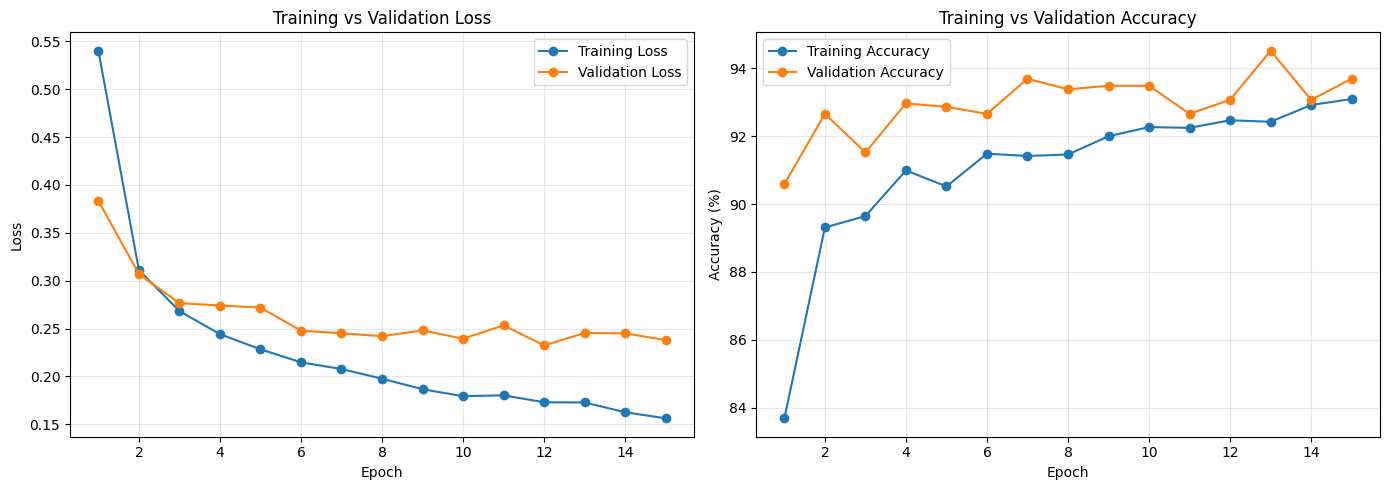

Training curves saved to models/training_curves.png


In [28]:
# 29. PLOT TRAINING AND VALIDATION CURVES

import matplotlib.pyplot as plt

epochs_completed = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(
    epochs_completed,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    epochs_completed,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(
    epochs_completed,
    [x * 100 for x in history["train_accuracy"]],
    marker="o",
    label="Training Accuracy"
)
axes[1].plot(
    epochs_completed,
    [x * 100 for x in history["val_accuracy"]],
    marker="o",
    label="Validation Accuracy"
)
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("models/training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

print("Training curves saved to models/training_curves.png")

/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Test Accuracy: 92.44%

Classification Report:
              precision    recall  f1-score   support

      Cattle     0.9715    0.9241    0.9472       738
     Buffalo     0.7344    0.9097    0.8127       155
       Other     0.9516    0.9440    0.9478       125

    accuracy                         0.9244      1018
   macro avg     0.8858    0.9259    0.9026      1018
weighted avg     0.9330    0.9244    0.9268      1018



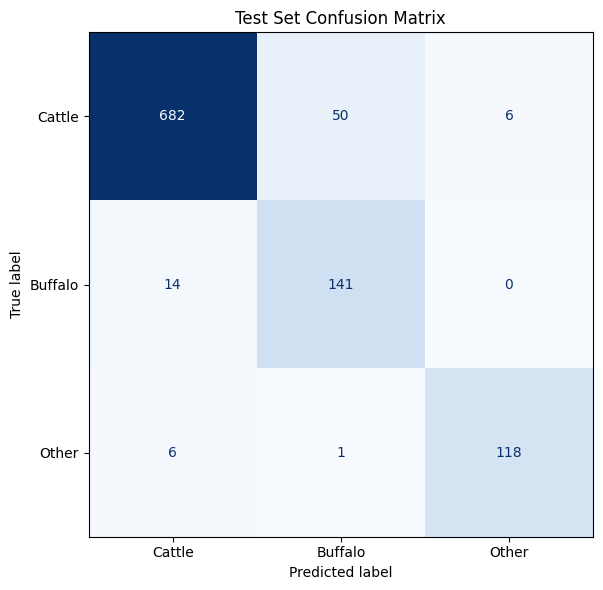


Confusion matrix saved to: models/confusion_matrix.png


In [29]:
# 30. EVALUATE MODEL ON TEST DATA

import numpy as np
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the best saved checkpoint
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)
model.eval()

y_true = []
y_pred = []

# Evaluate without calculating gradients
with torch.inference_mode():
    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.tolist())

# Overall accuracy
test_accuracy = accuracy_score(y_true, y_pred)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Test Set Confusion Matrix")
plt.tight_layout()
plt.savefig(
    MODEL_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nConfusion matrix saved to:", MODEL_DIR / "confusion_matrix.png")

In [30]:
# 31. ANALYZE INCORRECT TEST PREDICTIONS

import numpy as np
import pandas as pd
import torch

# Use the best saved model
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)
model.eval()

all_probabilities = []
all_targets = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )
        all_targets.extend(labels.numpy().tolist())


# Convert probabilities into predictions
all_probabilities = np.array(all_probabilities)
predicted_indices = all_probabilities.argmax(axis=1)

# Align results with the test dataframe
test_results = test_df.reset_index(drop=True).copy()

test_results["true_label"] = [
    idx_to_class[i] for i in all_targets
]

test_results["predicted_label"] = [
    idx_to_class[i] for i in predicted_indices
]

test_results["confidence"] = all_probabilities.max(axis=1)
test_results["correct"] = (
    test_results["true_label"]
    == test_results["predicted_label"]
)

# Display error counts by true and predicted class
errors = test_results[~test_results["correct"]].copy()

print("Correct predictions:", test_results["correct"].sum())
print("Incorrect predictions:", len(errors))

print("\nMisclassification counts:")
display(
    pd.crosstab(
        errors["true_label"],
        errors["predicted_label"],
        rownames=["Actual"],
        colnames=["Predicted"]
    )
)

print("\nFirst 15 incorrect predictions:")
display(
    errors[
        [
            "image_id",
            "true_label",
            "predicted_label",
            "confidence",
            "full_path"
        ]
    ].head(15)
)

/home/victus/Workspace/Deeplearning_Env/dlenv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Correct predictions: 941
Incorrect predictions: 77

Misclassification counts:


Predicted,Buffalo,Cattle,Other
Actual,,,
Buffalo,0,14,0
Cattle,50,0,6
Other,1,6,0



First 15 incorrect predictions:


,image_id,true_label,predicted_label,confidence,full_path
19,Krishna_Valley_55.jpg,Cattle,Buffalo,0.900231,dataset/main/Indian_bovine_breeds/Krishna_Vall...
22,Alambadi_60.png,Cattle,Buffalo,0.545047,dataset/main/Indian_bovine_breeds/Alambadi/Ala...
30,Holstein_Friesian_9.jpg,Cattle,Buffalo,0.732443,dataset/main/Indian_bovine_breeds/Holstein_Fri...
38,Brown_Swiss_50.jpg,Cattle,Buffalo,0.722711,dataset/main/Indian_bovine_breeds/Brown_Swiss/...
44,Screenshot (1145).png,Cattle,Buffalo,0.580628,dataset/main/Indian_bovine_breeds/Malnad_gidda...
62,Kangayam_68.jpg,Cattle,Buffalo,0.424180,dataset/main/Indian_bovine_breeds/Kangayam/Kan...
63,00000009.jpg,Cattle,Buffalo,0.818763,dataset/main/Indian_bovine_breeds/Kasargod/000...
70,Screenshot (1148).png,Cattle,Buffalo,0.769533,dataset/main/Indian_bovine_breeds/Malnad_gidda...
72,fb458618-000764,Other,Cattle,0.632111,dataset/other/Popular Animals Dataset/images/f...
79,Kangayam_54.jpg,Cattle,Buffalo,0.519455,dataset/main/Indian_bovine_breeds/Kangayam/Kan...


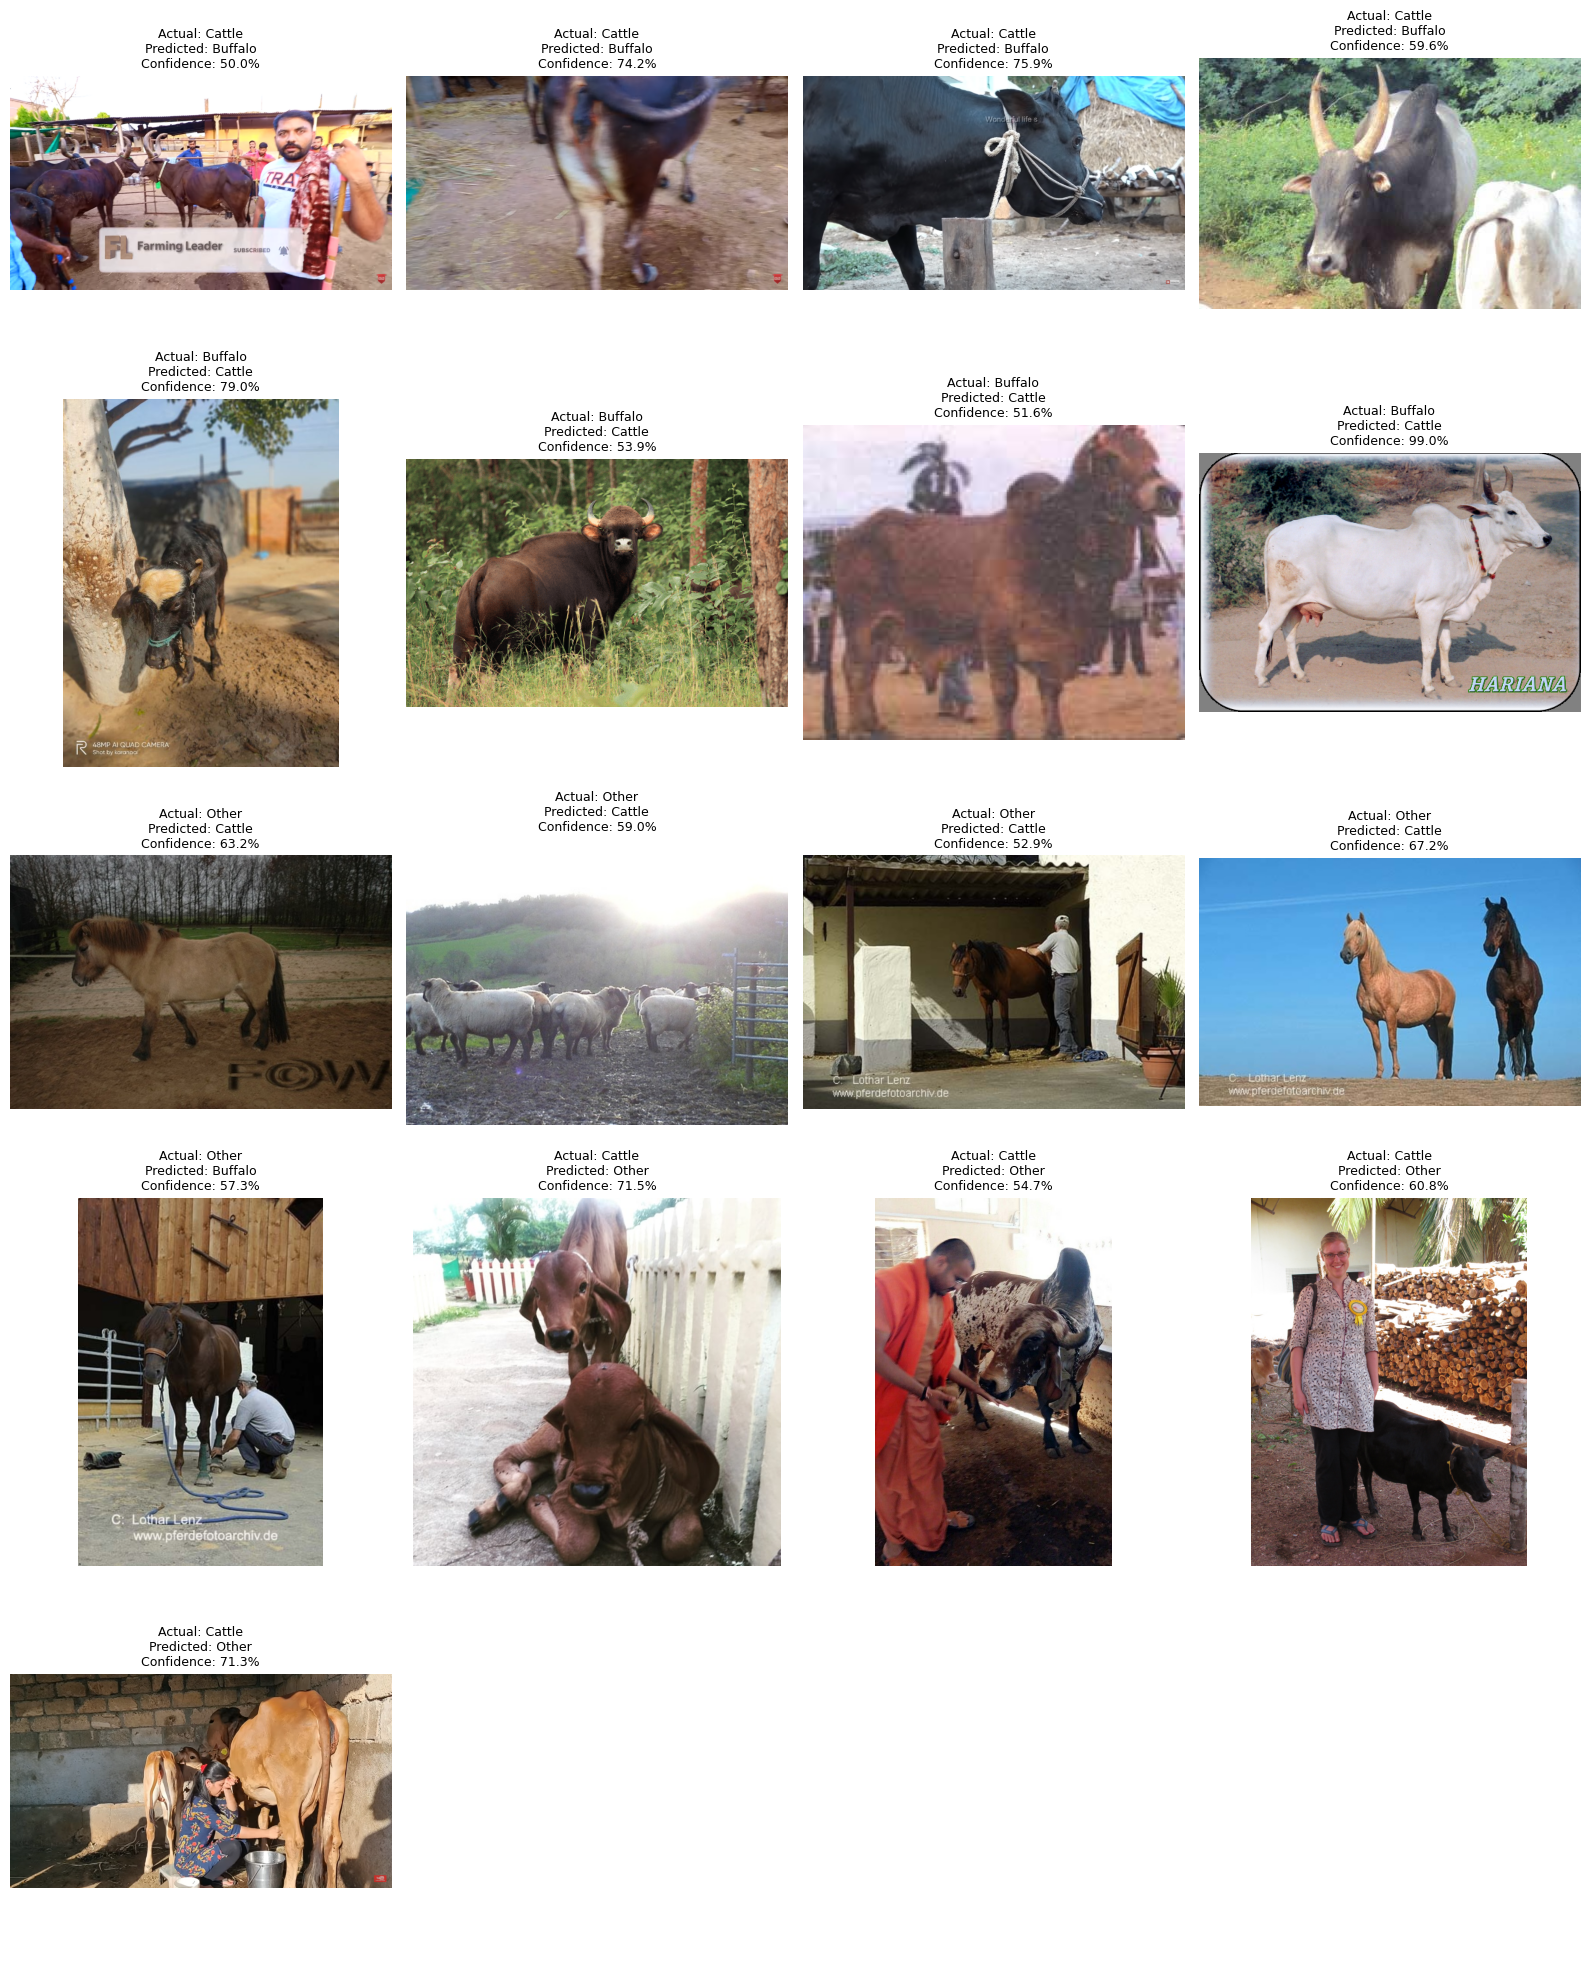

In [31]:
# 32. VISUALIZE MISCLASSIFIED TEST IMAGES

import matplotlib.pyplot as plt
from PIL import Image

# Select examples from the main error groups
error_groups = [
    ("Cattle", "Buffalo"),
    ("Buffalo", "Cattle"),
    ("Other", "Cattle"),
    ("Other", "Buffalo"),
    ("Cattle", "Other"),
]

samples_per_group = 4
selected_errors = []

for actual, predicted in error_groups:
    group = test_results[
        (test_results["true_label"] == actual) &
        (test_results["predicted_label"] == predicted)
    ]

    if len(group) > 0:
        selected_errors.append(
            group.sample(
                n=min(samples_per_group, len(group)),
                random_state=42
            )
        )

if not selected_errors:
    print("No misclassified images found.")
else:
    selected_errors_df = pd.concat(
        selected_errors,
        ignore_index=True
    )

    n_images = len(selected_errors_df)
    n_cols = 4
    n_rows = (n_images + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 4 * n_rows)
    )
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes, selected_errors_df.iterrows()
    ):
        try:
            with Image.open(row["full_path"]) as img:
                image = img.convert("RGB")

            ax.imshow(image)
            ax.set_title(
                f"Actual: {row['true_label']}\n"
                f"Predicted: {row['predicted_label']}\n"
                f"Confidence: {row['confidence']:.1%}",
                fontsize=9
            )
            ax.axis("off")

        except Exception as e:
            ax.set_title(f"Could not load image:\n{e}")

    plt.tight_layout()
    plt.show()

Predicted class: Other
Confidence: 99.47%

Probabilities:
Cattle    : 0.40%
Buffalo   : 0.13%
Other     : 99.47%


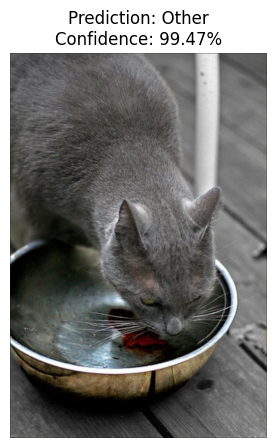

In [32]:
# 33. SINGLE-IMAGE PREDICTION

import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Load the best checkpoint
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)
model.eval()


def predict_image(image_path):

    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # Handle images that contain palette transparency
    with Image.open(image_path) as img:
        image = img.convert("RGBA").convert("RGB")

    # Apply the same preprocessing used during evaluation
    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    # Predict
    with torch.inference_mode():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()
    predicted_class = idx_to_class[predicted_index]
    confidence = probabilities[predicted_index].item()

    class_probabilities = {
        CLASS_NAMES[i]: round(probabilities[i].item() * 100, 2)
        for i in range(len(CLASS_NAMES))
    }

    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence * 100:.2f}%")

    print("\nProbabilities:")
    for class_name, probability in class_probabilities.items():
        print(f"{class_name:10}: {probability:.2f}%")

    # Display image and prediction
    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

    return {
        "predicted_class": predicted_class,
        "confidence": confidence,
        "probabilities": class_probabilities
    }


# Test with an image from the existing test set
sample_image_path = test_df.iloc[0]["full_path"]

result = predict_image(sample_image_path)